# Elección de la frecuencia de corte del filtro ambiente nuevo

Ítem 5 del plan de trabajo: *"construcción de un nuevo filtro no criogénico con una frecuencia
de corte única para todos los canales [...] teniendo en cuenta que el filtro cumpla su función
pero que tenga el menor tiempo de respuesta posible"*.

Este notebook responde dos cosas:

1. **La pregunta de Fran:** rampa de corriente de −1 µA a 80 µA en pasos de 10 nA, repetida
   10⁴ veces. ¿Cuánto tarda una medición (una rampa) y cuánto las 10⁴, con cada filtro?
2. **Qué $f_c$ (y qué $R$, $C$) conviene para el filtro nuevo**, con un criterio explícito que se
   pueda re-correr si cambian los requisitos.

**Modelo.** El mismo que ya está validado en `Simulaciones_filtros.ipynb` y
`Simulaciones_filtros_corriente.ipynb`: escalera R–C en espacio de estados, plegada al modo
diferencial ($R' = 2R_{ta}$, $C' = C_{ta}/2$ en el ambiente; $R' = 2R_{cry}$, $C' = C_{cry}$ en el
criogénico), excitada con **fuente de corriente** (el Keithley) y con salida = **corriente por la
juntura**. Se usa solo el par de corriente: durante la medición de $I_{sw}$ la juntura está en
voltaje cero, así que el par de sensado no se carga.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import linalg, optimize, signal

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# ---------------- PARÁMETROS (editables) ----------------
I_INI, I_FIN = -1e-6, 80e-6        # rampa de Fran [A]
PASO = 10e-9                       # paso de la rampa [A] (Fran: 10 nA)
N_PUNTOS = int(round((I_FIN - I_INI)/PASO)) + 1   # puntos por rampa
N_REP = 10_000                     # repeticiones
EPS = 0.01                         # criterio: error en la juntura al leer <= EPS * paso
T_MIN_INSTR = 10e-3                # tiempo por punto usado en la tesis (§5.3.2) [s]

R_CRY, C_CRY = 22.0, 47e-9         # filtro criogénico (no se cambia)
C_J = 50e-12                       # carga capacitiva de la juntura (tesis)
R_N = 74.0                         # R normal medida (§5.3.2)
R_SG = 62e3                        # R subgap medida (§5.3.2)
F_C_CRY = 28.8e3                   # f_c del criogénico calculada (Python y LTspice)

FILTROS_ACTUALES = pd.DataFrame([   # Tabla 5.1 de la tesis
    (150, 2.2e-6, 180), (150, 1.0e-6, 396), (51, 2.2e-6, 530),
    (51, 1.0e-6, 1165), (15, 2.2e-6, 1801), (15, 1.0e-6, 3962)],
    columns=["R_ta", "C_ta", "fc_tesis"])
K_FC = np.sqrt((np.sqrt(53) - 7) / 2)   # 0,37424: fc = K/(2πRC) para RC-RC sin buffer
print(f"K = {K_FC:.5f}")


K = 0.37424


## Paso 1: modelo

`escalera(...)` arma las matrices $A$, $B$, $C$ con Kirchhoff en cada nodo capacitivo.
`R_J = 0` representa la juntura en el estado de voltaje cero (un corto: la inductancia
Josephson, $L_J = \Phi_0/2\pi I_c \approx 14$ pH, es despreciable a estas frecuencias).

**Tiempo por punto.** La rampa es una escalera: cada $T$ segundos la corriente sube $\Delta I$.
La corriente en la juntura es la superposición de las respuestas al escalón de todos los
pasos anteriores, así que, en régimen, el error al final de cada punto es

$$\frac{e(T)}{\Delta I} = \sum_{k=1}^{\infty} r(kT), \qquad r(t) = 1 - \frac{y_{escalón}(t)}{y(\infty)}.$$

El tiempo por punto $T$ es el que hace $e(T) = \varepsilon\,\Delta I$. **No depende de $\Delta I$**
(el sistema es lineal): si se cambia el paso, cada punto tarda lo mismo y lo único que cambia es la
cantidad de puntos.


In [2]:
def escalera(Rs, Cs, R_J=0.0, C_J=C_J, fuente="corriente"):
    '''Escalera plegada. Rs[0]: de la fuente al nodo 0; Rs[k]: entre nodo k-1 y k;
    Rs[-1]: del último nodo con C a la juntura. Cs[k]: C a masa del nodo k.
    R_J = 0: juntura en corto (voltaje cero). Devuelve (A, B, C_salida); salida = I_juntura.'''
    n = len(Cs); assert len(Rs) == n + 1
    m = n + (1 if R_J > 0 else 0)
    Ceff = np.array(list(Cs) + ([C_J] if R_J > 0 else []), dtype=float)
    G = np.zeros((m, m)); B = np.zeros(m); Cout = np.zeros(m)
    def con(i, j, R):                      # conductancia entre i y j (j = -1: masa)
        g = 1 / R; G[i, i] += g
        if j >= 0: G[j, j] += g; G[i, j] -= g; G[j, i] -= g
    if fuente == "corriente": B[0] = 1.0
    else: con(0, -1, Rs[0]); B[0] = 1 / Rs[0]
    for k in range(1, n): con(k - 1, k, Rs[k])
    if R_J > 0:
        con(n - 1, n, Rs[n]); con(n, -1, R_J); Cout[n] = 1 / R_J
    else:
        con(n - 1, -1, Rs[n]); Cout[n - 1] = 1 / Rs[n]
    return -G / Ceff[:, None], B / Ceff, Cout


def cadena(R_ta, C_ta, R_J=0.0, fuente="corriente", con_crio=True):
    '''Ambiente (2 etapas) + criogénico (3 R, 2 C entre líneas), plegado diferencial.'''
    if con_crio:
        Rs = [2*R_ta, 2*R_ta, 2*R_CRY, 2*R_CRY, 2*R_CRY]
        Cs = [C_ta/2, C_ta/2, C_CRY, C_CRY]
    else:
        # solo ambiente, salida abierta: la salida es la tensión del último C
        A, B, _ = escalera([2*R_ta, 2*R_ta, 1.0], [C_ta/2, C_ta/2], R_J=0.0, fuente=fuente)
        n = len(B); A = A.copy()
        A[n-1, n-1] += 1/(1.0*C_ta/2)       # saco la R ficticia de 1 Ω a masa
        Cout = np.zeros(n); Cout[-1] = 1.0
        return A, B, Cout
    return escalera(Rs, Cs, R_J, fuente=fuente)


def H(sis, f):
    A, B, Cs = sis; s = 2j*np.pi*np.atleast_1d(f)
    return np.array([Cs @ np.linalg.solve(x*np.eye(len(B)) - A, B) for x in s])


def residuo(sis, t):
    '''r(t) = 1 - y(t)/y(inf) para un escalón, por autovalores. Devuelve (r, tau_lento).'''
    A, B, Cs = sis
    w, V = linalg.eig(A); b = linalg.solve(V, B); c = Cs @ V
    coef = -(c * b) / w
    yinf = np.real(coef.sum())
    t = np.atleast_1d(t)
    r = np.real((coef[None, :] * np.exp(np.outer(t, w))).sum(1)) / yinf
    return r, -1 / np.real(w).max()


def error_escalera(sis, T):
    _, tau = residuo(sis, [0.0])
    K = int(np.ceil(40 * tau / T)) + 5
    return residuo(sis, T * np.arange(1, K + 1))[0].sum()


def t_punto(sis, eps=EPS):
    '''Tiempo por punto para que el error de la escalera sea eps * paso.'''
    _, tau = residuo(sis, [0.0])
    g = lambda lT: np.log(max(error_escalera(sis, 10**lT), 1e-300)) - np.log(eps)
    return 10**optimize.brentq(g, np.log10(tau) - 4, np.log10(tau) + 4)


def t_punto_peor(R_ta, C_ta, eps=EPS, cargas=(0.0, R_N)):
    '''Peor caso entre juntura en voltaje cero y en estado normal.'''
    return max(t_punto(cadena(R_ta, C_ta, R_J=rj), eps) for rj in cargas)


def fc_tension(R_ta, C_ta):
    '''f_c "de catálogo": solo ambiente, fuente de tensión ideal, salida abierta (Tabla 5.1).'''
    sis = cadena(R_ta, C_ta, fuente="tension", con_crio=False)
    dc = abs(H(sis, 1e-3)[0])
    g = lambda lf: abs(H(sis, 10**lf)[0]) / dc - 1/np.sqrt(2)
    return 10**optimize.brentq(g, -1, 7)


### Validación

1. La $f_c$ "de catálogo" (tensión, salida abierta) tiene que reproducir la Tabla 5.1.
2. La fórmula de la escalera tiene que coincidir con una simulación temporal directa
   (`signal.lsim`) de 60 escalones.


In [3]:
val = FILTROS_ACTUALES.copy()
val["fc_modelo"] = [fc_tension(r.R_ta, r.C_ta) for r in val.itertuples()]
val["fc_formula"] = K_FC / (2*np.pi*val.R_ta*val.C_ta)
val["dif_%"] = 100*(val.fc_modelo - val.fc_tesis)/val.fc_tesis
print(val.round(2).to_string(index=False))

# escalera: fórmula vs simulación temporal
sis = cadena(150, 2.2e-6, R_J=0.0)
T = t_punto(sis, 0.01)
A, B, Cs = sis
ss = signal.StateSpace(A, B[:, None], Cs[None, :], 0)
n = 60; t = np.linspace(0, n*T, n*400 + 1); u = np.floor(t/T) + 1
_, y, _ = signal.lsim(ss, u, t)
yinf = np.real(-(Cs @ np.linalg.solve(A, B)))
i = int(round(59*T/(t[1]-t[0]))) - 1
print(f"\nCanal 150 Ω / 2,2 µF, T = {T*1e3:.3f} ms: error simulado = {u[i] - y[i]/yinf:.5f} pasos (fórmula: 0.01000)")


 R_ta  C_ta  fc_tesis  fc_modelo  fc_formula  dif_%
  150   0.0       180     180.49      180.49   0.27
  150   0.0       396     397.08      397.08   0.27
   51   0.0       530     530.86      530.86   0.16
   51   0.0      1165    1167.88     1167.88   0.25
   15   0.0      1801    1804.91     1804.91   0.22
   15   0.0      3962    3970.80     3970.80   0.22



Canal 150 Ω / 2,2 µF, T = 2.556 ms: error simulado = 0.01006 pasos (fórmula: 0.01000)


## Paso 2: tiempo por punto de los 6 filtros actuales

Para tres criterios de asentamiento ($\varepsilon$ = 10 %, 1 % y 0,1 % del paso) y para las dos
cargas: juntura en voltaje cero ($R_J = 0$) y en estado normal ($R_N$ = 74 Ω). Se toma el peor.


In [4]:
filas = []
for r in FILTROS_ACTUALES.itertuples():
    d = dict(R_ta=r.R_ta, C_uF=r.C_ta*1e6, fc_Hz=r.fc_tesis)
    for e in (0.1, 0.01, 0.001):
        d[f"T_{e:g} [ms]"] = 1e3*t_punto_peor(r.R_ta, r.C_ta, e)
    d["tau_lento [ms]"] = 1e3*max(residuo(cadena(r.R_ta, r.C_ta, R_J=rj), [0])[1] for rj in (0, R_N))
    filas.append(d)
tabla_T = pd.DataFrame(filas)
print(tabla_T.round(3).to_string(index=False))
print(f"\nRango de f_c: x{tabla_T.fc_Hz.max()/tabla_T.fc_Hz.min():.0f}.  "
      f"Rango de tiempo por punto (1 %): x{tabla_T['T_0.01 [ms]'].max()/tabla_T['T_0.01 [ms]'].min():.1f}")


 R_ta  C_uF  fc_Hz  T_0.1 [ms]  T_0.01 [ms]  T_0.001 [ms]  tau_lento [ms]
  150   2.2    180       1.744        3.256         4.811           0.678
  150   1.0    396       0.804        1.499         2.213           0.311
   51   2.2    530       1.309        2.475         3.678           0.524
   51   1.0   1165       0.608        1.148         1.705           0.243
   15   2.2   1801       1.168        2.232         3.331           0.479
   15   1.0   3962       0.545        1.039         1.550           0.223

Rango de f_c: x22.  Rango de tiempo por punto (1 %): x3.1


**Lectura.** Las $f_c$ van de 180 a 3962 Hz (factor 22), pero el tiempo por punto solo cambia un
factor ~3. Con fuente de corriente, la primera $R_{ta}$ no hace nada (la fuente empuja la misma
corriente igual) y el primer capacitor se descarga a través de todo lo que hay después:
$2R_{ta}$ + las tres $R_{cry}$ plegadas (132 Ω) + la juntura. En los canales de 15 y 51 Ω eso lo
dominan el criogénico y la juntura, no el filtro ambiente. **Lo que más pesa es la $C$**: los
canales de 1 µF son ~2 veces más rápidos que los de 2,2 µF con cualquier $R$.

Consistencia con la tesis: para $I_{sw}$ usó el filtro de 1801 Hz con 10 ms por punto; el modelo
pide ~2,2 ms al 1 %, así que esos 10 ms estaban holgados.


## Paso 3: la pregunta de Fran

Rampa de −1 µA a 80 µA en pasos de 10 nA (8101 puntos), 10⁴ repeticiones. Para cada filtro: cuánto
dura **una** medición (una rampa) y cuánto las 10⁴. Dos escenarios:

- **límite del filtro**: cada punto dura justo lo que el filtro necesita ($\varepsilon$ = 1 %);
- **10 ms por punto**: lo que se usó en la tesis (el instrumento, no el filtro, fija el tiempo).


In [5]:
def fmt(seg):
    if seg < 3600: return f"{seg/60:.1f} min"
    if seg < 86400: return f"{seg/3600:.1f} h"
    return f"{seg/86400:.1f} días"

def fila_fran(nombre, Tp):
    Ti = max(Tp, T_MIN_INSTR)
    return {"filtro": nombre, "T/punto [ms]": round(Tp*1e3, 2),
            "1 medición [s]": round(N_PUNTOS*Tp, 1), "10⁴ mediciones": fmt(N_REP*N_PUNTOS*Tp),
            "1 medición, 10 ms/pto [s]": round(N_PUNTOS*Ti, 1),
            "10⁴, 10 ms/pto": fmt(N_REP*N_PUNTOS*Ti)}

print(f"Rampa de {I_INI*1e6:g} a {I_FIN*1e6:g} µA en pasos de {PASO*1e9:g} nA: {N_PUNTOS} puntos\n")
fran = pd.DataFrame([fila_fran(f"{r.R_ta:g} Ω / {r.C_uF:g} µF ({r.fc_Hz:g} Hz)", r["T_0.01 [ms]"]*1e-3)
                     for _, r in tabla_T.iterrows()])
print(fran.to_string(index=False))


Rampa de -1 a 80 µA en pasos de 10 nA: 8101 puntos

                 filtro  T/punto [ms]  1 medición [s] 10⁴ mediciones  1 medición, 10 ms/pto [s] 10⁴, 10 ms/pto
150 Ω / 2.2 µF (180 Hz)          3.26            26.4       3.1 días                       81.0       9.4 días
  150 Ω / 1 µF (396 Hz)          1.50            12.1       1.4 días                       81.0       9.4 días
 51 Ω / 2.2 µF (530 Hz)          2.48            20.1       2.3 días                       81.0       9.4 días
  51 Ω / 1 µF (1165 Hz)          1.15             9.3       1.1 días                       81.0       9.4 días
15 Ω / 2.2 µF (1801 Hz)          2.23            18.1       2.1 días                       81.0       9.4 días
  15 Ω / 1 µF (3962 Hz)          1.04             8.4         23.4 h                       81.0       9.4 días


**Lectura.**

- Limitada por el filtro, **una medición** (una rampa de 8101 puntos) dura entre ~8 s (1 µF) y
  ~26 s (150 Ω / 2,2 µF). Las 10⁴ mediciones, entre ~1 y ~3 días.
- Con 10 ms por punto (como la tesis) el filtro **deja de importar**: 81 s por medición y 9,4 días
  las 10⁴, para cualquiera de los seis. Ahí lo que manda es el instrumento.
- Si no se pone un tiempo de espera fijo sino el que pide el filtro, el filtro sí importa: el más
  lento tarda 3 veces más que el más rápido.
- En la medición real de $I_{sw}$ la rampa se corta al saltar (~24 µA para la juntura de 8 µm) y
  lejos del salto se usan pasos grandes, así que el tiempo real es mucho menor. Pero la
  comparación entre filtros es la misma: el cociente entre ellos no cambia.


## Paso 4: barrido continuo de $f_c$

Para cada $C$ fija, se barre la $f_c$ "de catálogo" (eligiendo $R = K/2\pi f_c C$) y se calcula el
tiempo por punto. Los seis filtros actuales aparecen como puntos.


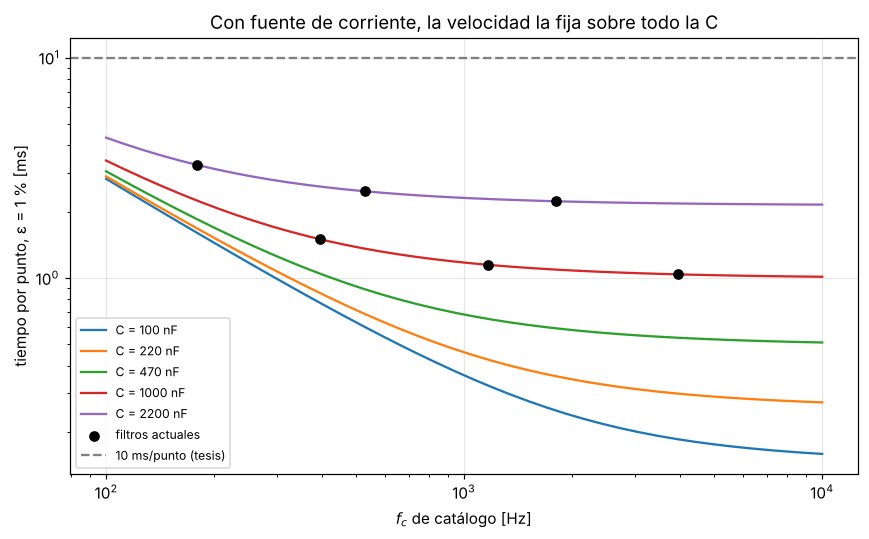

In [6]:
fcs = np.logspace(np.log10(100), np.log10(1e4), 40)
Cs_lista = [100e-9, 220e-9, 470e-9, 1e-6, 2.2e-6]
fig, ax = plt.subplots(figsize=(8, 5))
curvas = {}
for Cc in Cs_lista:
    Tp = np.array([t_punto_peor(K_FC/(2*np.pi*f*Cc), Cc) for f in fcs])
    curvas[Cc] = Tp
    ax.loglog(fcs, Tp*1e3, label=f"C = {Cc*1e9:g} nF")
ax.scatter(tabla_T.fc_Hz, tabla_T["T_0.01 [ms]"], c="k", zorder=5, label="filtros actuales")
ax.axhline(T_MIN_INSTR*1e3, ls="--", c="gray", label="10 ms/punto (tesis)")
ax.set_xlabel("$f_c$ de catálogo [Hz]"); ax.set_ylabel("tiempo por punto, ε = 1 % [ms]")
ax.set_title("Con fuente de corriente, la velocidad la fija sobre todo la C")
ax.legend(fontsize=8); plt.tight_layout()
plt.savefig("fig_tpunto_vs_fc.pdf"); plt.savefig("fig_tpunto_vs_fc.png", dpi=150); plt.show()


**Lectura.** Cada curva tiene un **codo**: por debajo, bajar la $f_c$ cuesta tiempo (la $R_{ta}$
pasa a dominar); por encima, subirla casi no acelera nada (dominan el criogénico y la juntura).
El codo está donde $2R_{ta}$ se hace comparable con lo que hay aguas abajo
($6R_{cry} + R_N \approx 206$ Ω), o sea $R_{ta} \sim 100$ Ω. Por eso el codo se corre a $f_c$ más
altas cuando la $C$ es más chica.


## Paso 5: criterio de elección

El filtro tiene que frenar dos tipos de ruido, y con fuente de corriente cada uno lo frena una
transferencia distinta:

- **Interferencia de tipo tensión** (pickup en cables, lazos de masa, lo que viene del lado del
  voltímetro): la frena la transferencia de tensión de siempre, $H_V$, la de la Tabla 5.1. Depende
  solo del producto $RC$, o sea de la $f_c$ de catálogo.
- **Ruido de corriente de la fuente**: lo frena la transferencia de corriente $H_I$ (fuente →
  juntura). Es **la misma** función que fija la velocidad: un filtro que frena más ruido de
  corriente es, necesariamente, más lento. Depende sobre todo de la $C$.

Cada uno se pide con una atenuación mínima a la frecuencia de referencia $f_{ref}$ = 28,8 kHz, la
$f_c$ del criogénico: el ambiente tiene que cubrir la banda donde el criogénico todavía no actúa.
El valor por defecto, 40 dB, sale de la medición: con la masa actual la curva se planta en una
meseta de −33 a −47 dB arriba de ~20 kHz (`salto_filtro_ambiente.ipynb`), así que pedir mucho
más no se puede verificar hasta mejorar la masa. **Este número es la decisión a acordar con Fran.**

**Problema de optimización:** entre todas las combinaciones comerciales ($R$ de la serie E24 entre
10 Ω y 9,1 kΩ, $C$ de la serie E6 entre 47 nF y 2,2 µF), minimizar el tiempo por punto sujeto a
$|H_V(f_{ref})| \le -A_V$ y $|H_I(f_{ref})| \le -A_I$.

Se informa también el tiempo por punto en la región subgap de la IV ($R_J = R_{sg}$), que escala
con $R_{sg}\,C$.


In [7]:
A_MIN_V = 40.0            # dB a F_REF, interferencia de tensión  (a definir con Fran)
A_MIN_I = 40.0            # dB a F_REF, ruido de corriente de la fuente (a definir con Fran)
F_REF = F_C_CRY

E24 = np.array([10,11,12,13,15,16,18,20,22,24,27,30,33,36,39,43,47,51,56,62,68,75,82,91], float)
R_COM = np.concatenate([E24, E24*10, E24*100])
C_COM = np.array([47, 68, 100, 150, 220, 330, 470, 680, 1000, 1500, 2200]) * 1e-9


def aten_V(R_ta, C_ta, f=F_REF):
    sis = cadena(R_ta, C_ta, fuente="tension", con_crio=False)
    return 20*np.log10(abs(H(sis, f)[0]) / abs(H(sis, 1e-3)[0]))


def aten_I(R_ta, C_ta, f=F_REF, R_J=0.0):
    sis = cadena(R_ta, C_ta, R_J=R_J)
    return 20*np.log10(abs(H(sis, f)[0]) / abs(H(sis, 1e-3)[0]))


filas = []
for Cc in C_COM:
    for Rr in R_COM:
        filas.append(dict(R=Rr, C_nF=Cc*1e9, fc_Hz=K_FC/(2*np.pi*Rr*Cc),
                          A_V=aten_V(Rr, Cc), A_I=aten_I(Rr, Cc)))
grilla = pd.DataFrame(filas)
# el tiempo solo hace falta en las combinaciones que cumplen (acelera mucho la cuenta)
grilla["T_ms"] = np.nan
cand = grilla[(grilla.A_V <= -min(A_MIN_V, 20)) & (grilla.A_I <= -min(A_MIN_I, 20))].index
for k in cand:
    grilla.loc[k, "T_ms"] = 1e3*t_punto_peor(grilla.R[k], grilla.C_nF[k]*1e-9)
print(f"{len(grilla)} combinaciones, {len(cand)} con tiempo calculado")


792 combinaciones, 593 con tiempo calculado


In [8]:
def elegir(A_V, A_I):
    ok = grilla[(grilla.A_V <= -A_V) & (grilla.A_I <= -A_I)].dropna(subset=["T_ms"])
    return None if ok.empty else ok.sort_values("T_ms").iloc[0]

g = elegir(A_MIN_V, A_MIN_I)
R_SEL, C_SEL = g.R, g.C_nF*1e-9
fc_sel = fc_tension(R_SEL, C_SEL)
T_sel = t_punto_peor(R_SEL, C_SEL)
T_sg = t_punto(cadena(R_SEL, C_SEL, R_J=R_SG), EPS)
print(f"Elección: R = {R_SEL:g} Ω, C = {C_SEL*1e9:g} nF  ->  f_c = {fc_sel:.0f} Hz")
print(f"  |H_V| a {F_REF/1e3:.1f} kHz: {g.A_V:.1f} dB    |H_I|: {g.A_I:.1f} dB   (pedido: -{A_MIN_V:g} / -{A_MIN_I:g})")
print(f"  tiempo por punto (ε = 1 %): {T_sel*1e3:.3f} ms   (subgap: {T_sg*1e3:.0f} ms)")
print(f"  una medición (-1 a 80 µA, 10 nA): {N_PUNTOS*T_sel:.1f} s;  10⁴ mediciones: {fmt(N_REP*N_PUNTOS*T_sel)}")
print("\nComparación con los filtros actuales (pregunta de Fran):")
comp = pd.concat([fran, pd.DataFrame([fila_fran(f"PROPUESTO {R_SEL:g} Ω / {C_SEL*1e9:g} nF ({fc_sel:.0f} Hz)", T_sel)])])
print(comp.to_string(index=False))


Elección: R = 330 Ω, C = 330 nF  ->  f_c = 547 Hz
  |H_V| a 28.8 kHz: -51.9 dB    |H_I|: -40.0 dB   (pedido: -40 / -40)
  tiempo por punto (ε = 1 %): 0.757 ms   (subgap: 122 ms)
  una medición (-1 a 80 µA, 10 nA): 6.1 s;  10⁴ mediciones: 17.0 h

Comparación con los filtros actuales (pregunta de Fran):
                           filtro  T/punto [ms]  1 medición [s] 10⁴ mediciones  1 medición, 10 ms/pto [s] 10⁴, 10 ms/pto
          150 Ω / 2.2 µF (180 Hz)          3.26            26.4       3.1 días                       81.0       9.4 días
            150 Ω / 1 µF (396 Hz)          1.50            12.1       1.4 días                       81.0       9.4 días
           51 Ω / 2.2 µF (530 Hz)          2.48            20.1       2.3 días                       81.0       9.4 días
            51 Ω / 1 µF (1165 Hz)          1.15             9.3       1.1 días                       81.0       9.4 días
          15 Ω / 2.2 µF (1801 Hz)          2.23            18.1       2.1 días              

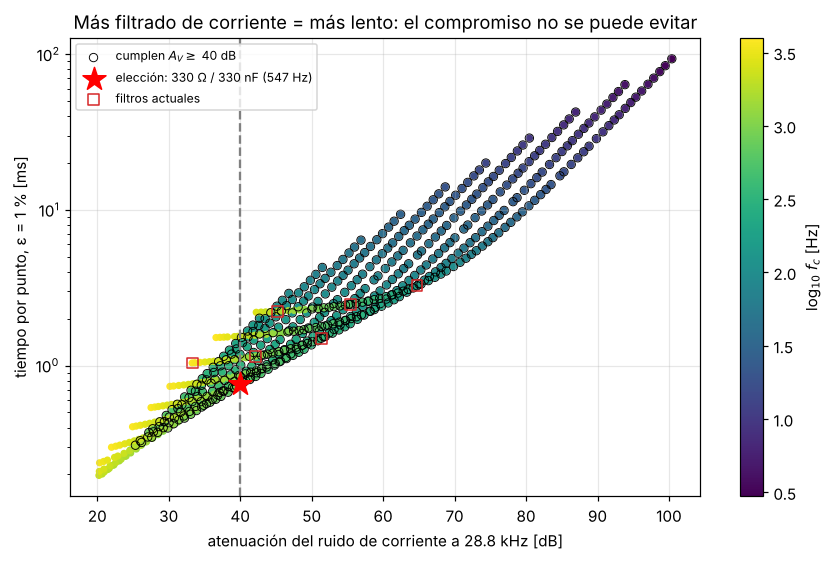

In [9]:
fig, ax = plt.subplots(figsize=(8, 5.2))
d = grilla.dropna(subset=["T_ms"])
sc = ax.scatter(-d.A_I, d.T_ms, c=np.log10(d.fc_Hz), cmap="viridis", s=14)
cb = plt.colorbar(sc, ax=ax); cb.set_label("log$_{10}$ $f_c$ [Hz]")
ok = d[(d.A_V <= -A_MIN_V)]
ax.scatter(-ok.A_I, ok.T_ms, facecolors="none", edgecolors="k", s=30, lw=0.6,
           label=f"cumplen $A_V \\geq$ {A_MIN_V:g} dB")
ax.axvline(A_MIN_I, ls="--", c="gray")
ax.scatter([-g.A_I], [g.T_ms], marker="*", s=250, c="red", zorder=5,
           label=f"elección: {g.R:g} Ω / {g.C_nF:g} nF ({fc_sel:.0f} Hz)")
act = FILTROS_ACTUALES
ax.scatter([-aten_I(r.R_ta, r.C_ta) for r in act.itertuples()],
           [1e3*t_punto_peor(r.R_ta, r.C_ta) for r in act.itertuples()],
           marker="s", c="none", edgecolors="tab:red", s=50, label="filtros actuales")
ax.set_yscale("log")
ax.set_xlabel(f"atenuación del ruido de corriente a {F_REF/1e3:.1f} kHz [dB]")
ax.set_ylabel("tiempo por punto, ε = 1 % [ms]")
ax.set_title("Más filtrado de corriente = más lento: el compromiso no se puede evitar")
ax.legend(fontsize=8, loc="upper left"); plt.tight_layout()
plt.savefig("fig_compromiso.pdf"); plt.savefig("fig_compromiso.png", dpi=150); plt.show()


**Lectura.**

- Los puntos forman un **borde**: para cada atenuación de corriente hay un tiempo mínimo que no se
  puede bajar. Los filtros óptimos están sobre ese borde.
- La condición de tensión ($A_V$) fija un techo para la $f_c$; la de corriente ($A_I$) fija un piso
  para la $C$. Entre las dos queda una sola combinación más rápida.
- Por qué no conviene ir a $C$ muy chica con $R$ grande (aunque a la misma $f_c$ sea más rápido):
  frena menos el ruido de la fuente. Y por qué no conviene $C$ grande: es más lento en todo, y en
  la región subgap muchísimo más.


### Sensibilidad a los requisitos

Como $A_V$ y $A_I$ son la decisión abierta, se muestra cómo cambia la elección.


In [10]:
filas = []
for av in (30, 40, 50):
    for ai in (30, 35, 40, 45):
        e = elegir(av, ai)
        if e is None:
            filas.append(dict(A_V=av, A_I=ai, eleccion="ninguna")); continue
        filas.append(dict(A_V=av, A_I=ai, eleccion=f"{e.R:g} Ω / {e.C_nF:g} nF",
                          fc_Hz=round(e.fc_Hz), T_punto_ms=round(e.T_ms, 3),
                          una_medicion_s=round(N_PUNTOS*e.T_ms*1e-3, 1),
                          diez_mil=fmt(N_REP*N_PUNTOS*e.T_ms*1e-3)))
sens = pd.DataFrame(filas)
print(sens.to_string(index=False))


 A_V  A_I       eleccion  fc_Hz  T_punto_ms  una_medicion_s diez_mil
  30   30 220 Ω / 220 nF   1231       0.416             3.4    9.4 h
  30   35 390 Ω / 220 nF    694       0.570             4.6   12.8 h
  30   40 330 Ω / 330 nF    547       0.757             6.1   17.0 h
  30   45 160 Ω / 680 nF    547       1.056             8.6   23.8 h
  40   30 430 Ω / 150 nF    923       0.423             3.4    9.5 h
  40   35 390 Ω / 220 nF    694       0.570             4.6   12.8 h
  40   40 330 Ω / 330 nF    547       0.757             6.1   17.0 h
  40   45 160 Ω / 680 nF    547       1.056             8.6   23.8 h
  50   30 2200 Ω / 47 nF    576       0.521             4.2   11.7 h
  50   35 750 Ω / 150 nF    529       0.634             5.1   14.3 h
  50   40 330 Ω / 330 nF    547       0.757             6.1   17.0 h
  50   45 160 Ω / 680 nF    547       1.056             8.6   23.8 h


## Resumen

- **Pregunta de Fran:** ver la tabla del Paso 3. Con el tiempo por punto fijado por el filtro, una
  rampa de −1 a 80 µA en pasos de 10 nA dura de ~8 a ~26 s, y 10⁴ rampas de ~1 a ~3 días. Con
  10 ms por punto (tesis), 81 s y 9,4 días para todos los filtros por igual. El filtro propuesto:
  ~6 s por rampa y ~17 h las 10⁴.
- **Resultado principal:** con fuente de corriente, la velocidad la fija sobre todo la $C$ y no la
  $f_c$. Subir la $f_c$ más allá del codo no acelera la medición.
- **Criterio:** la combinación comercial más rápida que atenúa al menos `A_MIN_V` (interferencia
  de tensión) y `A_MIN_I` (ruido de corriente de la fuente) a la $f_c$ del criogénico. Con 40 y
  40 dB sale la combinación impresa en el Paso 5.

**Supuestos a revisar:** resistencia del cableado del criostato no incluida (cables no
superconductores la suben y hacen todo más lento); par de sensado no incluido (en estado normal y
subgap carga el nodo de la juntura y alarga los tiempos, ver `Simulaciones_filtros_4lineas.ipynb`);
fuente de corriente ideal; tolerancia de los capacitores (−7 a −11 % medida en el salto).
